# Efficient tracker vs full-frame baseline

The baseline is a TrackNet-style U-Net. Every frame it sees six RGB frames at 640×360 and returns a heatmap. That network is about 11.3 million parameters, and one forward is 350.65 G FLOPs.

The efficient tracker is not a smaller copy of that net. It keeps a constant-velocity adaptive Kalman filter on the ball and runs a 119k-parameter crop U-Net on a window around the prediction, growing the crop when the peak is weak. The full baseline stays loaded and is called only to start a track, when position uncertainty exceeds 50 px, or after a miss. The filter itself is a few hundred FLOPs.

This notebook scores both on the **train** games (game1–game7). A frame counts only when it has a label and both systems already have a position. Distance is in source pixels on the 1280×720 frame. The timer starts after the frames are in memory. The CDF below is titled `train error`.

The setup cell is the run whose outputs are saved here: start with the baseline, call it again above 50 px of uncertainty, and call it on a miss. The first crop still starts at the smallest side (`start_at_uncertainty = False`).


In [1]:
# Load both networks. The hybrid calls the full baseline only to start a track,
# when uncertainty exceeds 50 px, or on a miss.

import csv
import time
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "base_akf.yaml").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W
import importlib

import tracking.efficient.model as efficient_model

importlib.reload(efficient_model)
from tracking.efficient.model import EfficientTracker, crop_sides

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset).resolve())

# Crop size, confidence, measurement clip, and baseline hooks: tracker.rules.
tracker = EfficientTracker()
tracker.rules.use_baseline_to_start = True # of note
tracker.rules.uncertainty_px = 50
tracker.rules.use_baseline_on_miss = True
# False: every frame grows from min_side. True: first crop covers the gate.
tracker.rules.start_at_uncertainty = False
baseline = tracker.baseline
cnn = tracker.cnn
device = tracker.device
num_diffs = tracker.num_diffs
num_frames = tracker.num_frames
channels_per_frame = tracker.channels_per_frame
in_ch = num_frames * channels_per_frame
out_w = tracker.out_w
out_h = tracker.out_h
forward_counts = tracker.forward_counts
MIN_SIDE = tracker.rules.min_side

VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}


def n_params(module: torch.nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())


def _ladder() -> list[int]:
    return crop_sides(tracker.rules)


def _sync() -> None:
    if device.type == "cuda":
        torch.cuda.synchronize()


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = Path(cfg["paths"]["dataset"]) / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            vis = int(row["visibility"] or 0)
            xy = None
            if vis > 0:
                xy = np.array(
                    [float(row["x-coordinate"]), float(row["y-coordinate"])],
                    dtype=np.float64,
                )
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "visibility": vis,
                    "status": int(row["status"] or 0),
                    "xy": xy,
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def read_rgb(path: Path) -> np.ndarray:
    """Model-resolution RGB, channel-first, matching BallDataset."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    if bgr.shape[1] != out_w or bgr.shape[0] != out_h:
        bgr = cv2.resize(bgr, (out_w, out_h), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(rgb.transpose(2, 0, 1))


def run_baseline(frames: list[dict]) -> list[dict | None]:
    """Heatmap argmax in source pixels. None until the N-frame window is full.

    Frames are read before the timer. ms covers the stack, the forward, and the argmax.
    """
    rgbs = [read_rgb(frame["path"]) for frame in frames]
    steps: list[dict | None] = []
    for i in range(len(frames)):
        if i < num_frames - 1:
            steps.append(None)
            continue
        _sync()
        t0 = time.perf_counter()
        window = rgbs[i - num_frames + 1 : i + 1]
        x = torch.from_numpy(np.concatenate(window, axis=0)).unsqueeze(0).to(device)
        with torch.inference_mode():
            heat = baseline(x)[0, 0]
        conf = float(heat.amax().item())
        flat = int(heat.argmax().item())
        height, width = heat.shape
        xy = np.array(
            [(flat % width) * (SRC_W / width), (flat // width) * (SRC_H / height)],
            dtype=np.float64,
        )
        _sync()
        steps.append({"xy": xy, "conf": conf, "ms": (time.perf_counter() - t0) * 1000.0})
    return steps


def run_akf(frames: list[dict]) -> list[dict | None]:
    """CNN crop ladder plus AKF posterior. None until the first accepted peak.

    Frames are read before the timer. ms on each step covers the difference,
    the crops, and the update. RGB frames are passed when a baseline hook is on.
    """
    grays = [read_gray(frame["path"]) for frame in frames]
    rgbs = [read_rgb(frame["path"]) for frame in frames] if tracker.needs_rgbs() else None
    return tracker.find_positions(grays, rgbs)


print(
    f"baseline  {tracker.baseline_checkpoint.relative_to(ROOT)}  {device}  "
    f"params={n_params(baseline):,}  input={in_ch}x{out_h}x{out_w}"
)
print(
    f"cnn+akf   {tracker.cnn_checkpoint.relative_to(ROOT)}  {device}  "
    f"params={n_params(cnn):,}  diffs={num_diffs}  "
    f"crop={tracker.rules.min_side}..{tracker.rules.max_side}  "
    f"start_at_uncertainty={tracker.rules.start_at_uncertainty}  "
    f"(AKF has no weights)"
)


baseline  models/baseline_cnn/saved_models/baseline_cnn_train1/baseline_cnn_train1.pt  cuda  params=11,334,017  input=9x360x640
cnn+akf   models/detection/cnn_detector/saved_models/cnn_detector/cnn_detector.pt  cuda  params=118,769  diffs=2  crop=48..720  start_at_uncertainty=False  (AKF has no weights)


## Train-split accuracy and cost

The next cell walks every train clip. Magenta on the CDF is the baseline heatmap peak. Blue is the hybrid posterior. The printed cost is mean and p95 FLOPs and milliseconds against a 33.3 ms frame (30 fps). Hybrid FLOPs are split into the crop CNN, the baseline hooks, and the filter.


game10/Clip1
game10/Clip10
game10/Clip11
game10/Clip12
game10/Clip2
game10/Clip3
game10/Clip4
game10/Clip5
game10/Clip6
game10/Clip7
game10/Clip8
game10/Clip9
test  both models have a position and the frame has a label  dist in source px  big miss > 50px
baseline = heatmap argmax    cnn+akf = filter posterior
scored=2044  skipped=38 labeled frames before both were ready
baseline          n= 2044  mean=  14.6  std=  66.9  median=   2.2  p95=  37.6  >50px=  4.5%
cnn+akf           n= 2044  mean=   4.8  std=  19.2  median=   1.5  p95=  13.7  >50px=  1.9%
movement  (mean dist)
  flying          n= 1940  base=  13.2  akf=   4.3
  hit             n=   48  base=  80.3  akf=  19.3
  bouncing        n=   56  base=   5.6  akf=   8.2
obscurity  (mean dist)
  visible         n= 1862  base=   8.3  akf=   4.0
  hard to see     n=  181  base=  77.0  akf=  12.0
  occluded        n=    1  base= 424.4  akf=  18.3


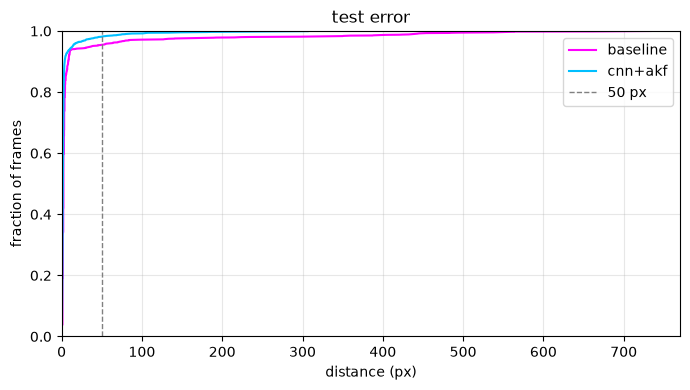

pipeline ms is after the frames are in memory (stack, crop or baseline forward, decode, AKF update)
baseline          params=11,334,017  flops mean=350.65 G  p95=350.65 G  ms mean= 17.34  std=  0.19  p95= 17.60   16.0 ms under 33.3
hybrid            params=11,452,786  flops mean= 62.79 G  p95=510.37 G  ms mean=  6.90  std= 15.75  p95= 56.07   26.4 ms under 33.3
hybrid flops from  crop  13.90 G  baseline  48.89 G  ssm    0.5 K  baseline called on 13.9% of frames
one forward  baseline 350.65 G  cnn@48 128.80 M
forward only  warmup=10  repeats=50  baseline  16.52 ms  cnn 48px   0.40 ms


In [2]:
# Train split (game1–game7). Distance is source pixels on frames where both
# systems already have a position and the frame has a label.

from torch.utils.flop_counter import FlopCounterMode

SPLIT = "test"
BIG_MISS_PX = 50.0
FRAME_MS = 1000.0 / 30.0
WARMUP, REPEATS = 10, 50


def count_flops(module: torch.nn.Module, example: torch.Tensor) -> int:
    with torch.inference_mode():
        with FlopCounterMode(display=False) as counter:
            module(example)
    return int(counter.get_total_flops())


def fmt_flops(n: float) -> str:
    if n >= 1e9:
        return f"{n / 1e9:.2f} G"
    if n >= 1e6:
        return f"{n / 1e6:.2f} M"
    return f"{n / 1e3:.1f} K"


flop_cnn = {
    side: count_flops(cnn, torch.zeros(1, num_diffs, side, side, device=device))
    for side in _ladder()
}
base_flops_one = count_flops(
    baseline, torch.zeros(1, in_ch, out_h, out_w, device=device)
)

# The timed pass should not include the first CUDA launch.
with torch.inference_mode():
    baseline(torch.zeros(1, in_ch, out_h, out_w, device=device))
    cnn(torch.zeros(1, num_diffs, MIN_SIDE, MIN_SIDE, device=device))
_sync()

forward_counts.clear()
base_err, akf_err = [], []
base_ms, akf_ms = [], []
base_flops, akf_flops = [], []
akf_crop_flops, akf_base_flops, akf_ssm_flops = [], [], []
visibility, movement = [], []
skipped = 0

root = Path(cfg["paths"]["dataset"])
for game in cfg["splits"][SPLIT]:
    game_dir = root / game
    if not game_dir.is_dir():
        raise FileNotFoundError(game_dir)
    for clip_dir in sorted(p for p in game_dir.iterdir() if p.is_dir()):
        print(f"{game}/{clip_dir.name}", flush=True)
        frames = load_clip(game, clip_dir.name)
        base_steps = run_baseline(frames)
        akf_steps = run_akf(frames)
        for frame, b, a in zip(frames, base_steps, akf_steps):
            if frame["xy"] is None:
                continue
            if b is None or a is None:
                skipped += 1
                continue
            base_err.append(float(np.hypot(*(b["xy"] - frame["xy"]))))
            akf_err.append(float(np.hypot(*(a["xy"] - frame["xy"]))))
            base_ms.append(b["ms"])
            akf_ms.append(a["ms"])
            base_flops.append(base_flops_one)
            crop = sum(n * flop_cnn[side] for side, n in a["forwards"])
            hook = a["baseline_forwards"] * base_flops_one
            ssm = a["ssm_flops"]
            akf_crop_flops.append(crop)
            akf_base_flops.append(hook)
            akf_ssm_flops.append(ssm)
            akf_flops.append(crop + hook + ssm)
            visibility.append(frame["visibility"])
            movement.append(frame["status"])

base_err = np.asarray(base_err, dtype=np.float64)
akf_err = np.asarray(akf_err, dtype=np.float64)
base_ms = np.asarray(base_ms, dtype=np.float64)
akf_ms = np.asarray(akf_ms, dtype=np.float64)
base_flops = np.asarray(base_flops, dtype=np.float64)
akf_flops = np.asarray(akf_flops, dtype=np.float64)
akf_crop_flops = np.asarray(akf_crop_flops, dtype=np.float64)
akf_base_flops = np.asarray(akf_base_flops, dtype=np.float64)
akf_ssm_flops = np.asarray(akf_ssm_flops, dtype=np.float64)
visibility = np.asarray(visibility)
movement = np.asarray(movement)

print(
    f"{SPLIT}  both models have a position and the frame has a label  "
    f"dist in source px  big miss > {BIG_MISS_PX:.0f}px"
)
print("baseline = heatmap argmax    cnn+akf = filter posterior")
print(f"scored={len(base_err)}  skipped={skipped} labeled frames before both were ready")


def show_accuracy(name: str, errs: np.ndarray) -> None:
    if len(errs) == 0:
        print(f"{name:16}  n=    0")
        return
    big = 100.0 * np.mean(errs > BIG_MISS_PX)
    print(
        f"{name:16}  n={len(errs):5d}  "
        f"mean={errs.mean():6.1f}  std={errs.std():6.1f}  "
        f"median={np.median(errs):6.1f}  p95={np.percentile(errs, 95):6.1f}  "
        f">{BIG_MISS_PX:.0f}px={big:5.1f}%"
    )


def show_group(name: str, mask: np.ndarray) -> None:
    count = int(mask.sum())
    if count == 0:
        return
    print(
        f"{name:16}  n={count:5d}  "
        f"base={base_err[mask].mean():6.1f}  "
        f"akf={akf_err[mask].mean():6.1f}"
    )


if len(base_err) == 0:
    print("no scored frames")
else:
    show_accuracy("baseline", base_err)
    show_accuracy("cnn+akf", akf_err)
    print("movement  (mean dist)")
    for code, name in MOVEMENT.items():
        show_group(f"  {name}", movement == code)
    print("obscurity  (mean dist)")
    for code, name in VISIBILITY.items():
        if code == 0:
            continue
        show_group(f"  {name}", visibility == code)

    fig, ax = plt.subplots(figsize=(7.0, 4.0))
    for errs, label, color in (
        (base_err, "baseline", "magenta"),
        (akf_err, "cnn+akf", "deepskyblue"),
    ):
        ordered = np.sort(errs)
        ax.plot(
            ordered,
            np.arange(1, len(ordered) + 1) / len(ordered),
            color=color,
            label=label,
        )
    ax.axvline(BIG_MISS_PX, color="0.5", ls="--", lw=1, label=f"{BIG_MISS_PX:.0f} px")
    ax.set_xlim(left=0)
    ax.set_ylim(0, 1)
    ax.set_xlabel("distance (px)")
    ax.set_ylabel("fraction of frames")
    ax.set_title(f"{SPLIT} error")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

    def show_cost(name: str, params: int, flops: np.ndarray, ms: np.ndarray) -> None:
        gap = FRAME_MS - float(ms.mean())
        side = "under" if gap >= 0 else "over"
        print(
            f"{name:16}  params={params:10,}  "
            f"flops mean={fmt_flops(flops.mean()):>8}  p95={fmt_flops(np.percentile(flops, 95)):>8}  "
            f"ms mean={ms.mean():6.2f}  std={ms.std():6.2f}  p95={np.percentile(ms, 95):6.2f}  "
            f"{abs(gap):5.1f} ms {side} {FRAME_MS:.1f}"
        )

    print(
        "pipeline ms is after the frames are in memory "
        "(stack, crop or baseline forward, decode, AKF update)"
    )
    uses_baseline = tracker.needs_rgbs()
    hybrid_params = n_params(cnn) + (n_params(baseline) if uses_baseline else 0)
    show_cost("baseline", n_params(baseline), base_flops, base_ms)
    show_cost("hybrid", hybrid_params, akf_flops, akf_ms)
    called = 100.0 * float(np.mean(akf_base_flops > 0))
    print(
        "hybrid flops from  "
        f"crop {fmt_flops(akf_crop_flops.mean()):>8}  "
        f"baseline {fmt_flops(akf_base_flops.mean()):>8}  "
        f"ssm {fmt_flops(akf_ssm_flops.mean()):>8}  "
        f"baseline called on {called:.1f}% of frames"
    )

    common_side = max(forward_counts, key=forward_counts.get) if forward_counts else MIN_SIDE
    base_x = torch.zeros(1, in_ch, out_h, out_w, device=device)
    cnn_x = torch.zeros(1, num_diffs, common_side, common_side, device=device)

    def forward_ms(fn) -> float:
        for _ in range(WARMUP):
            fn()
        _sync()
        t0 = time.perf_counter()
        for _ in range(REPEATS):
            fn()
        _sync()
        return (time.perf_counter() - t0) / REPEATS * 1000.0

    def run_base():
        with torch.inference_mode():
            baseline(base_x)

    def run_cnn():
        with torch.inference_mode():
            cnn(cnn_x)

    print(f"one forward  baseline {fmt_flops(base_flops_one)}  cnn@{common_side} {fmt_flops(flop_cnn[common_side])}")
    print(
        f"forward only  warmup={WARMUP}  repeats={REPEATS}  "
        f"baseline {forward_ms(run_base):6.2f} ms  "
        f"cnn {common_side}px {forward_ms(run_cnn):6.2f} ms"
    )


## One clip

game1/Clip1, frames 0001.jpg through 0050.jpg. This clip is inside the train split, so it is a close look at the same run, not a held-out test. Lime is the label, magenta the baseline, blue the hybrid.


game1/Clip1  0001.jpg → 0050.jpg
file        move      vis              base      akf  closer
0001.jpg    flying    visible             —        —  —
0002.jpg    flying    visible           1.0      1.0  tie
0003.jpg    flying    visible           3.0      2.9  akf
0004.jpg    flying    visible           1.0      1.7  base
0005.jpg    flying    visible           1.4      0.8  akf
0006.jpg    flying    visible           1.0      0.4  akf
0007.jpg    flying    visible           1.0      0.5  akf
0008.jpg    flying    visible           1.0      1.1  base
0009.jpg    flying    visible           0.0      0.8  base
0010.jpg    flying    visible           1.0      1.2  base
0011.jpg    flying    visible           1.0      0.5  akf
0012.jpg    flying    visible           1.4      0.5  akf
0013.jpg    flying    visible           1.0      0.5  akf
0014.jpg    flying    visible           1.0      1.5  base
0015.jpg    flying    visible           1.4      0.4  akf
0016.jpg    flying    visible    

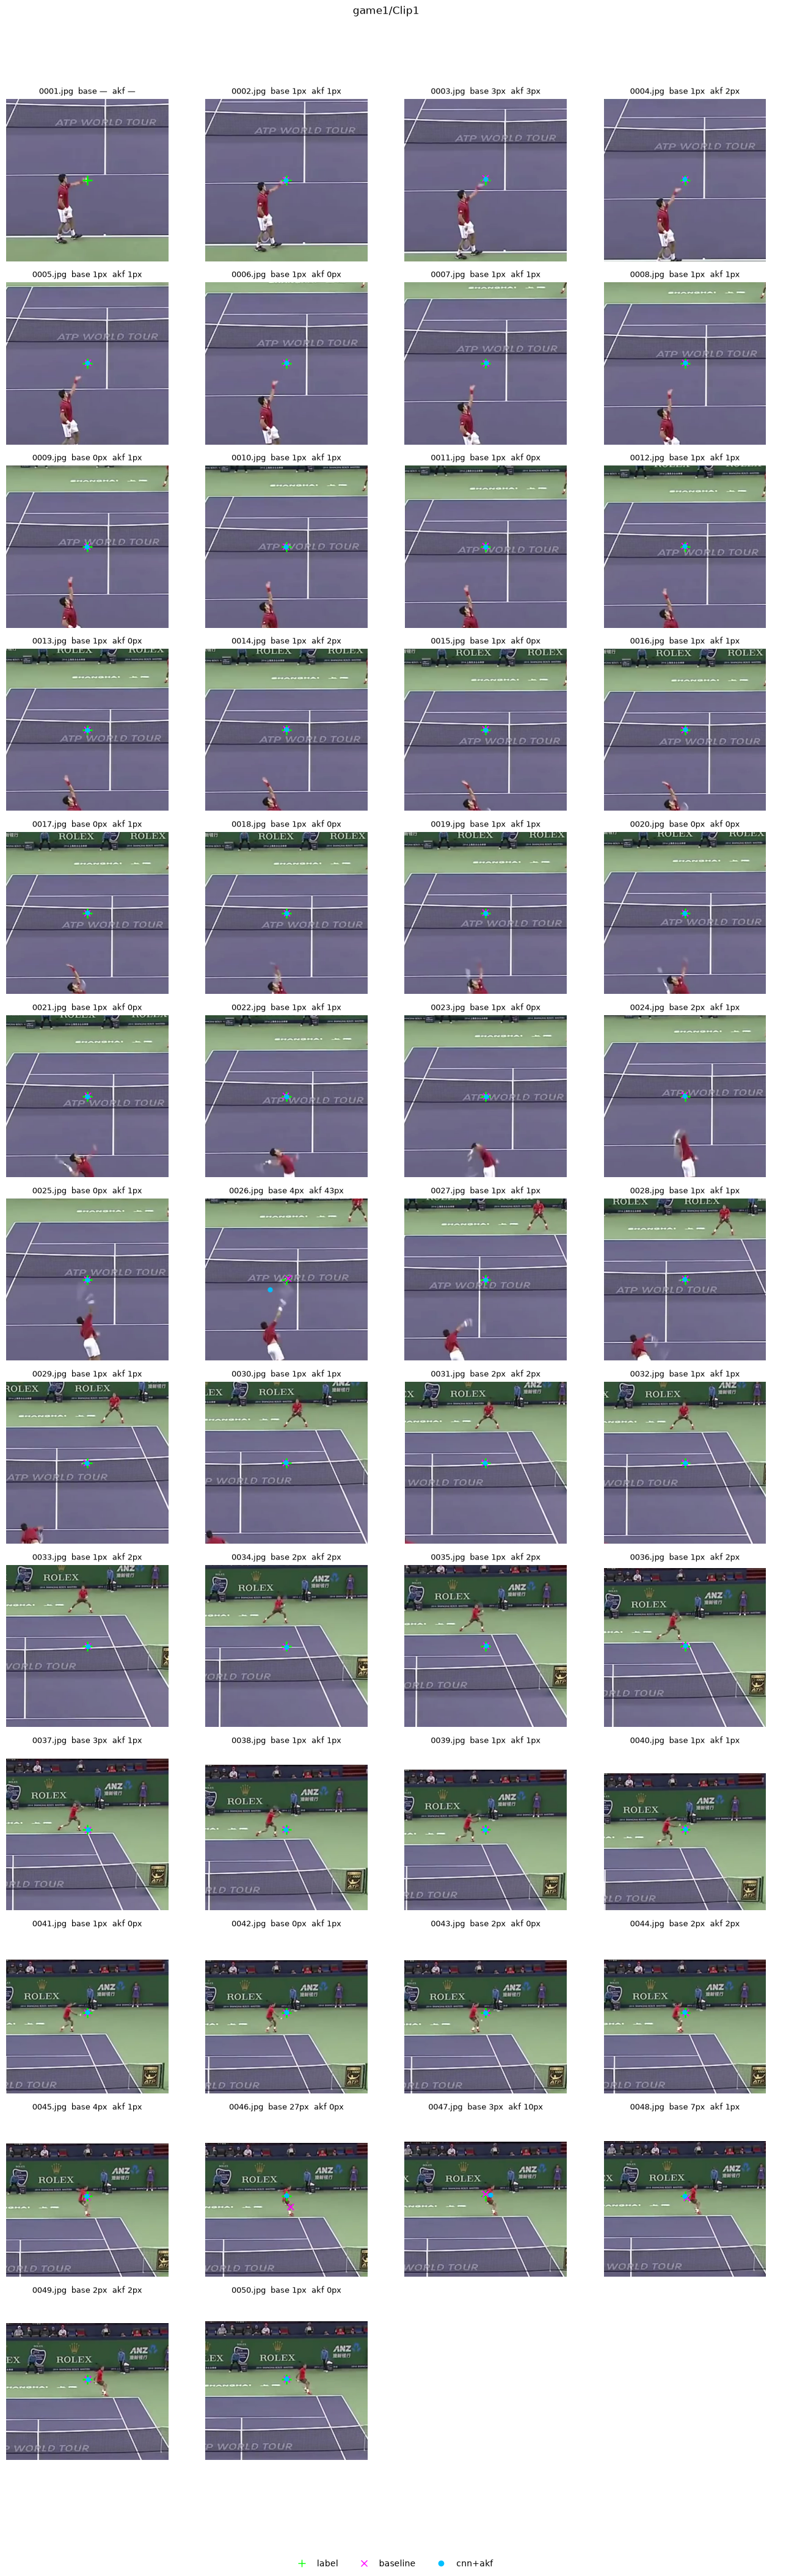

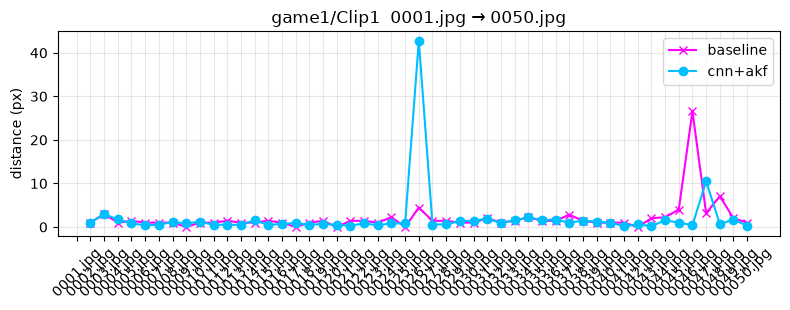

In [4]:
# game1/Clip1, the first 50 frames. Lime is the label, magenta the baseline,
# blue the hybrid posterior.

from matplotlib.lines import Line2D

GAME, CLIP = "game1", "Clip1"
START, COUNT = "0001.jpg", 50

clip = load_clip(GAME, CLIP)
start = next(i for i, frame in enumerate(clip) if frame["file"] == START)
end = min(start + COUNT, len(clip))
window = range(start, end)
base_steps = run_baseline(clip)
akf_steps = run_akf(clip)

print(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[end - 1]['file']}")
print(f"{'file':10}  {'move':8}  {'vis':12}  {'base':>7}  {'akf':>7}  closer")

base_window, akf_window = [], []
for i in window:
    frame, b, a = clip[i], base_steps[i], akf_steps[i]
    xy = frame["xy"]
    be = float(np.hypot(*(b["xy"] - xy))) if b is not None and xy is not None else float("nan")
    ae = float(np.hypot(*(a["xy"] - xy))) if a is not None and xy is not None else float("nan")
    base_window.append(be)
    akf_window.append(ae)
    if np.isfinite(be) and np.isfinite(ae):
        if abs(be - ae) < 0.05:
            closer = "tie"
        elif be < ae:
            closer = "base"
        else:
            closer = "akf"
    else:
        closer = "—"
    be_txt = f"{be:7.1f}" if np.isfinite(be) else "      —"
    ae_txt = f"{ae:7.1f}" if np.isfinite(ae) else "      —"
    print(
        f"{frame['file']:10}  {MOVEMENT[frame['status']]:8}  "
        f"{VISIBILITY[frame['visibility']]:12}  {be_txt}  {ae_txt}  {closer}"
    )

base_window = np.asarray(base_window, dtype=np.float64)
akf_window = np.asarray(akf_window, dtype=np.float64)
both = np.isfinite(base_window) & np.isfinite(akf_window)
n_both = int(both.sum())
if n_both == 0:
    print("no labeled frame in this window with both positions")
else:
    print(
        f"window  n={n_both}  "
        f"base mean={base_window[both].mean():.1f}  "
        f"median={np.median(base_window[both]):.1f}  "
        f"std={base_window[both].std():.1f}  "
        f"akf mean={akf_window[both].mean():.1f}  "
        f"median={np.median(akf_window[both]):.1f}  "
        f"std={akf_window[both].std():.1f}"
    )

half = 180
ncols = 4
nrows = int(np.ceil(len(window) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.3 * nrows))
for ax, i in zip(np.atleast_1d(axes).ravel(), window):
    frame, b, a = clip[i], base_steps[i], akf_steps[i]
    bgr = cv2.imread(str(frame["path"]), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(frame["path"])
    if bgr.shape[1] != SRC_W or bgr.shape[0] != SRC_H:
        bgr = cv2.resize(bgr, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    xy = frame["xy"]
    if xy is not None:
        center = xy
    elif a is not None:
        center = a["xy"]
    elif b is not None:
        center = b["xy"]
    else:
        center = np.array([SRC_W / 2, SRC_H / 2])
    if xy is not None:
        ax.plot(*xy, "+", color="lime", ms=11, mew=1.8)
    if b is not None:
        ax.plot(*b["xy"], "x", color="magenta", ms=7, mew=1.4)
    if a is not None:
        ax.plot(*a["xy"], "o", color="deepskyblue", ms=5)
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] + half, center[1] - half)
    be = f"{base_window[i - start]:.0f}px" if np.isfinite(base_window[i - start]) else "—"
    ae = f"{akf_window[i - start]:.0f}px" if np.isfinite(akf_window[i - start]) else "—"
    ax.set_title(f"{frame['file']}  base {be}  akf {ae}", fontsize=9)
    ax.axis("off")

for ax in np.atleast_1d(axes).ravel()[len(window) :]:
    ax.axis("off")

fig.legend(
    handles=[
        Line2D([0], [0], marker="+", color="lime", lw=0, ms=8, label="label"),
        Line2D([0], [0], marker="x", color="magenta", lw=0, ms=7, label="baseline"),
        Line2D([0], [0], marker="o", color="deepskyblue", lw=0, ms=6, label="cnn+akf"),
    ],
    loc="lower center",
    ncol=3,
    frameon=False,
)
fig.suptitle(f"{GAME}/{CLIP}", fontsize=12)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()

fig, ax = plt.subplots(figsize=(8.0, 3.2))
names = [clip[i]["file"] for i in window]
ax.plot(names, base_window, color="magenta", marker="x", label="baseline")
ax.plot(names, akf_window, color="deepskyblue", marker="o", label="cnn+akf")
ax.set_ylabel("distance (px)")
ax.set_title(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[end - 1]['file']}")
ax.tick_params(axis="x", labelrotation=45)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
